In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans,DBSCAN
from sklearn.metrics import silhouette_score

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier

from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix)

In [57]:
df = pd.read_csv('/content/Crop_recommendationV2.csv')

In [58]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 23 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   N                       2200 non-null   int64  
 1   P                       2200 non-null   int64  
 2   K                       2200 non-null   int64  
 3   temperature             2200 non-null   float64
 4   humidity                2200 non-null   float64
 5   ph                      2200 non-null   float64
 6   rainfall                2200 non-null   float64
 7   label                   2200 non-null   object 
 8   soil_moisture           2200 non-null   float64
 9   soil_type               2200 non-null   int64  
 10  sunlight_exposure       2200 non-null   float64
 11  wind_speed              2200 non-null   float64
 12  co2_concentration       2200 non-null   float64
 13  organic_matter          2200 non-null   float64
 14  irrigation_frequency    2200 non-null   

In [59]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall,soil_moisture,soil_type,sunlight_exposure,...,organic_matter,irrigation_frequency,crop_density,pest_pressure,fertilizer_usage,growth_stage,urban_area_proximity,water_source_type,frost_risk,water_usage_efficiency
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,...,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655,20.151388,1.991364,8.570609,...,5.465652,3.515000,12.344959,49.850701,125.846403,1.999545,24.801013,2.003636,50.304701,2.990268
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389,5.793720,0.812263,1.999382,...,2.605294,1.697912,4.297494,28.886354,43.564527,0.818999,14.523975,0.812021,28.580352,1.139637
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267,10.024260,1.000000,5.000710,...,1.003338,1.000000,5.004341,0.038103,50.209990,1.000000,0.017756,1.000000,0.054911,1.002106
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686,15.179949,1.000000,6.904620,...,3.203903,2.000000,8.585734,24.379866,88.030737,1.000000,12.212594,1.000000,26.104674,2.051814
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624,20.088481,2.000000,8.609968,...,5.418049,4.000000,12.303616,49.982421,126.441536,2.000000,24.922548,2.000000,50.171934,2.968675
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508,25.255146,3.000000,10.220394,...,7.686417,5.000000,15.975567,74.681904,163.850536,3.000000,37.322761,3.000000,75.262676,3.968736
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117,29.997860,3.000000,11.991041,...,9.999990,6.000000,19.988474,99.983849,199.982166,3.000000,49.992046,3.000000,99.957274,4.997130


In [60]:
df.shape

(2200, 23)

In [61]:
df.duplicated().sum()

np.int64(0)

In [62]:
df.isnull().sum()

,0
N,0
P,0
K,0
temperature,0
humidity,0
ph,0
rainfall,0
label,0
soil_moisture,0
soil_type,0


**EDA**

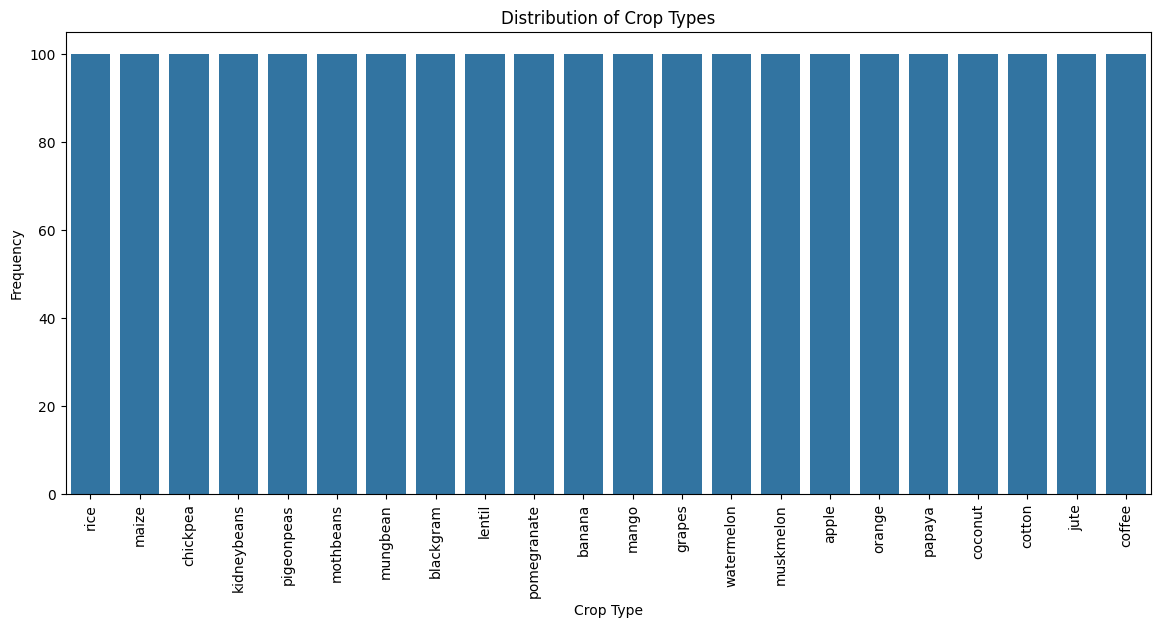

In [63]:
plt.figure(figsize=(14,6))
sns.countplot(data=df, x='label')
plt.xticks(rotation=90)
plt.title("Distribution of Crop Types")
plt.xlabel("Crop Type")
plt.ylabel("Frequency")
plt.show()

*The count plot shows the number of observations for each crop type in the dataset. A relatively balanced distribution indicates that all crop categories are well represented, which is beneficial for classification models because it minimizes class imbalance. If one crop dominated the dataset, the model could become biased toward predicting that class. The balanced distribution therefore supports the development of accurate and reliable crop prediction models.*

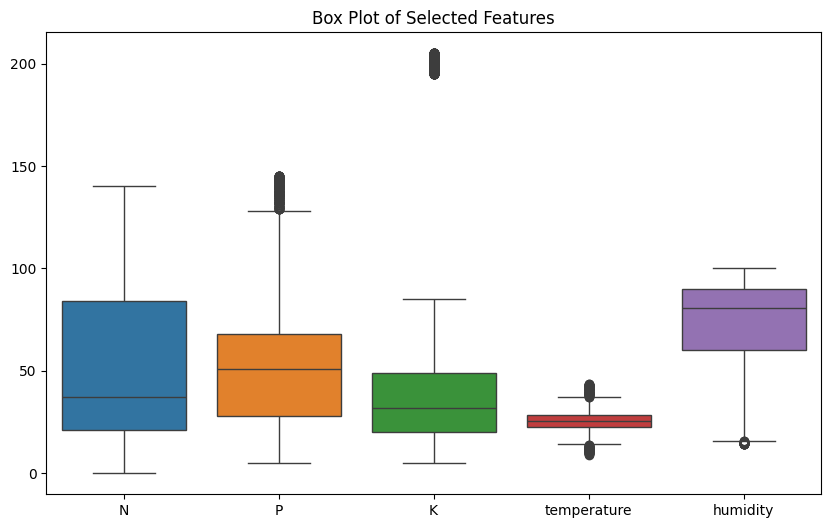

In [64]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df[['N','P','K','temperature','humidity']])
plt.title("Box Plot of Selected Features")
plt.show()

*The box plot summarizes each feature using its median, quartiles, and potential outliers. Outliers appear as individual points beyond the whiskers and may represent extreme environmental conditions or measurement errors. In agricultural datasets, such observations are often meaningful because they may correspond to unusual climate events or soil conditions. This visualization helps determine whether preprocessing techniques such as outlier treatment are necessary.*

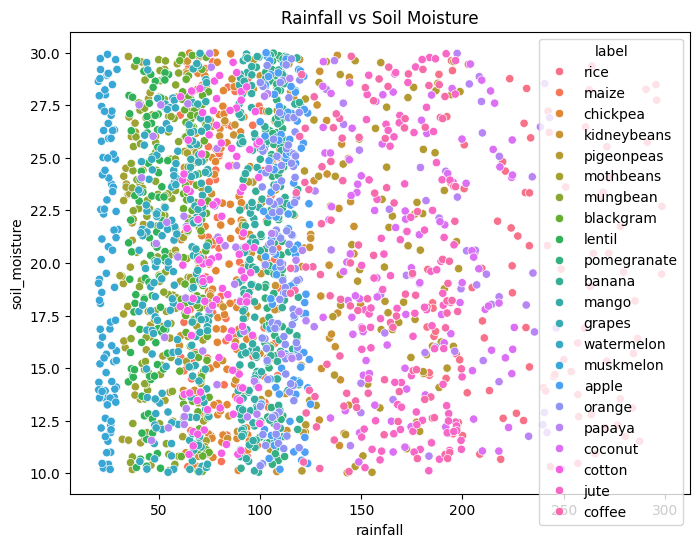

In [65]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='rainfall',
    y='soil_moisture',
    hue='label'
)
plt.title("Rainfall vs Soil Moisture")
plt.show()

*The scatter plot examines the relationship between rainfall and soil moisture. A positive relationship is expected because increased rainfall generally raises soil moisture levels. The different crop colors reveal whether particular crops are associated with specific environmental conditions. This visualization also helps identify clusters, trends, and unusual observations that may influence crop growth.*

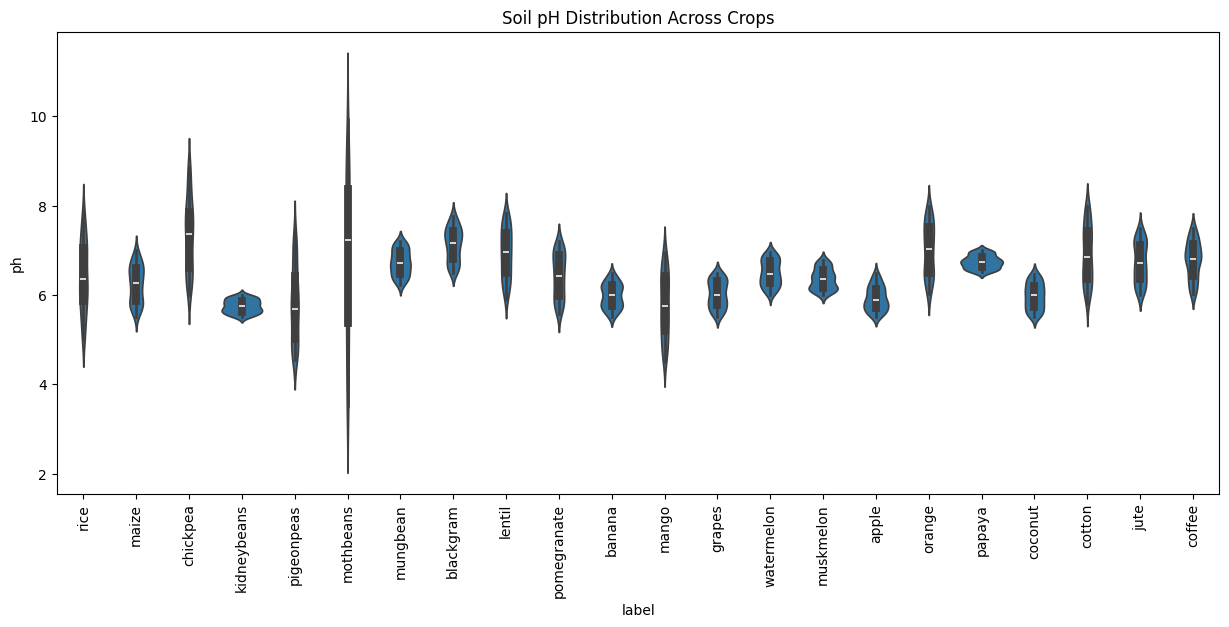

In [66]:
plt.figure(figsize=(15,6))
sns.violinplot(
    data=df,
    x='label',
    y='ph'
)
plt.xticks(rotation=90)
plt.title("Soil pH Distribution Across Crops")
plt.show()

*The violin plot combines the features of a box plot and a density plot, providing detailed information about the distribution of soil pH for each crop. Wider sections indicate regions where observations are more concentrated, while narrower sections represent fewer observations. This chart helps determine whether specific crops require narrow pH ranges or can tolerate broader soil acidity conditions.*

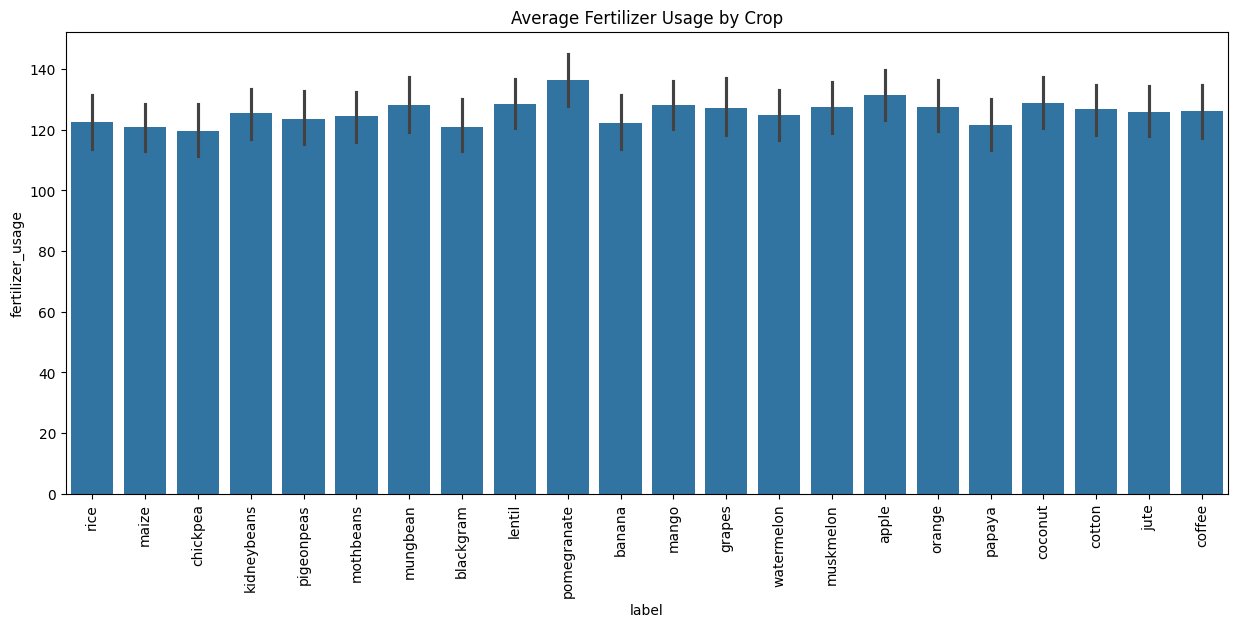

In [67]:
plt.figure(figsize=(15,6))
sns.barplot(
    data=df,
    x='label',
    y='fertilizer_usage'
)

plt.xticks(rotation=90)
plt.title("Average Fertilizer Usage by Crop")
plt.show()

*The bar chart compares the average fertilizer usage among different crop types. Differences in bar heights indicate variations in nutrient requirements and agricultural practices. Crops with higher fertilizer usage may demand greater nutrient supplementation, while lower values may indicate crops that naturally thrive with fewer external inputs. Such insights are useful for precision agriculture and fertilizer optimization.*

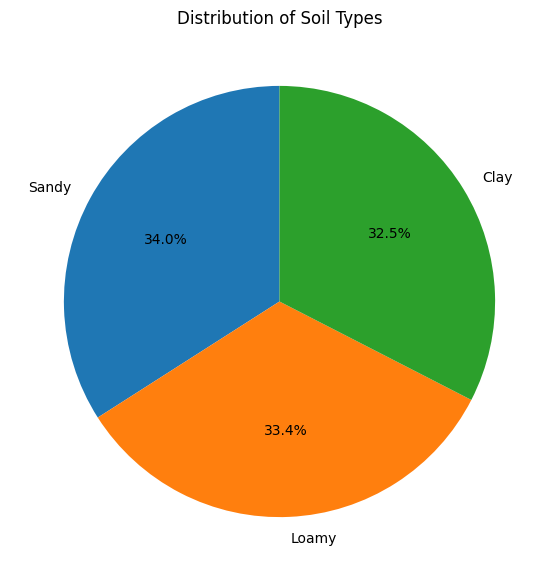

In [68]:
soil_counts = df['soil_type'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(
    soil_counts,
    labels=['Sandy','Loamy','Clay'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Distribution of Soil Types")
plt.show()

*The pie chart illustrates the proportion of each soil type represented in the dataset. It provides a quick overview of whether the observations are evenly distributed among sandy, loamy, and clay soils or whether one soil type dominates. A balanced distribution suggests that the dataset captures a wide range of farming conditions, allowing machine learning models to learn from diverse soil environments. Conversely, if one soil type occupies a significantly larger proportion, the resulting models may become more influenced by conditions associated with that soil type.*

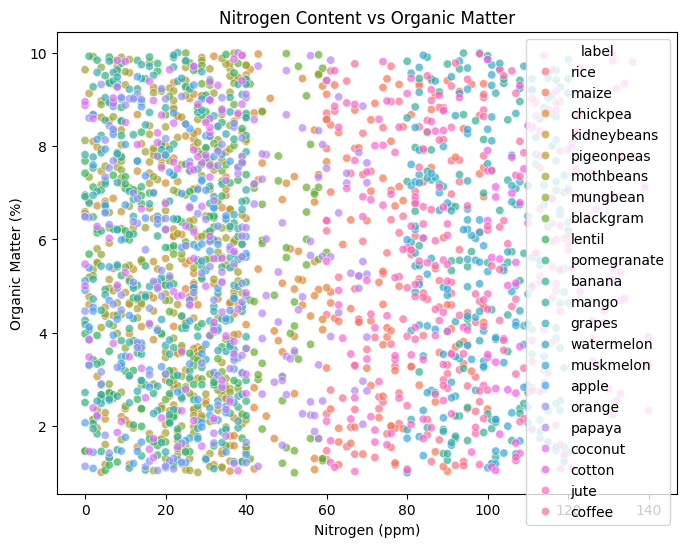

In [69]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='N',
    y='organic_matter',
    hue='label',
    alpha=0.7
)
plt.title("Nitrogen Content vs Organic Matter")
plt.xlabel("Nitrogen (ppm)")
plt.ylabel("Organic Matter (%)")
plt.show()

*This scatter plot explores the relationship between nitrogen concentration and soil organic matter. Higher organic matter often contributes to improved nitrogen availability because decomposing organic material releases nutrients into the soil. The visualization helps determine whether nutrient-rich soils consistently contain higher organic matter and whether different crop types are associated with distinct soil fertility conditions.*

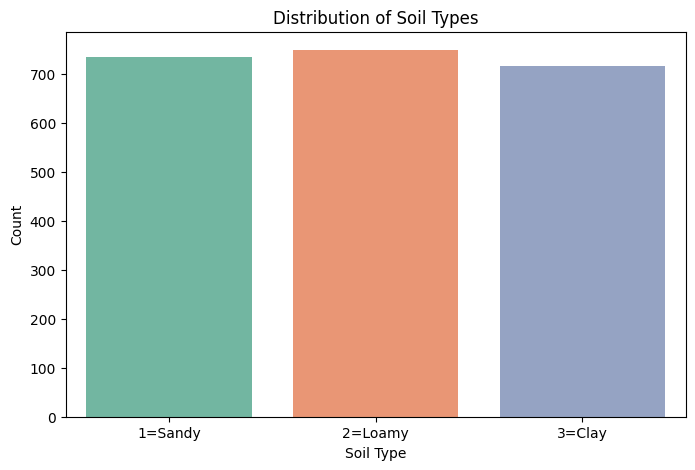

In [70]:
plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x='soil_type',
    hue='soil_type',
    palette='Set2',
    legend=False
)

plt.title("Distribution of Soil Types")
plt.xlabel("Soil Type")
plt.ylabel("Count")
plt.xticks([0,1,2], ['1=Sandy','2=Loamy','3=Clay']) # Reverted xticks to match typical countplot indexing
plt.show()

*This count plot illustrates the frequency of each soil type in the dataset. It helps determine whether the dataset includes a balanced representation of sandy, loamy, and clay soils. A balanced distribution improves the ability of machine learning models to learn patterns across different soil conditions, while an uneven distribution may bias the model toward the most common soil type. Understanding soil composition is also important because soil characteristics significantly influence nutrient availability, water retention, and crop productivity.*

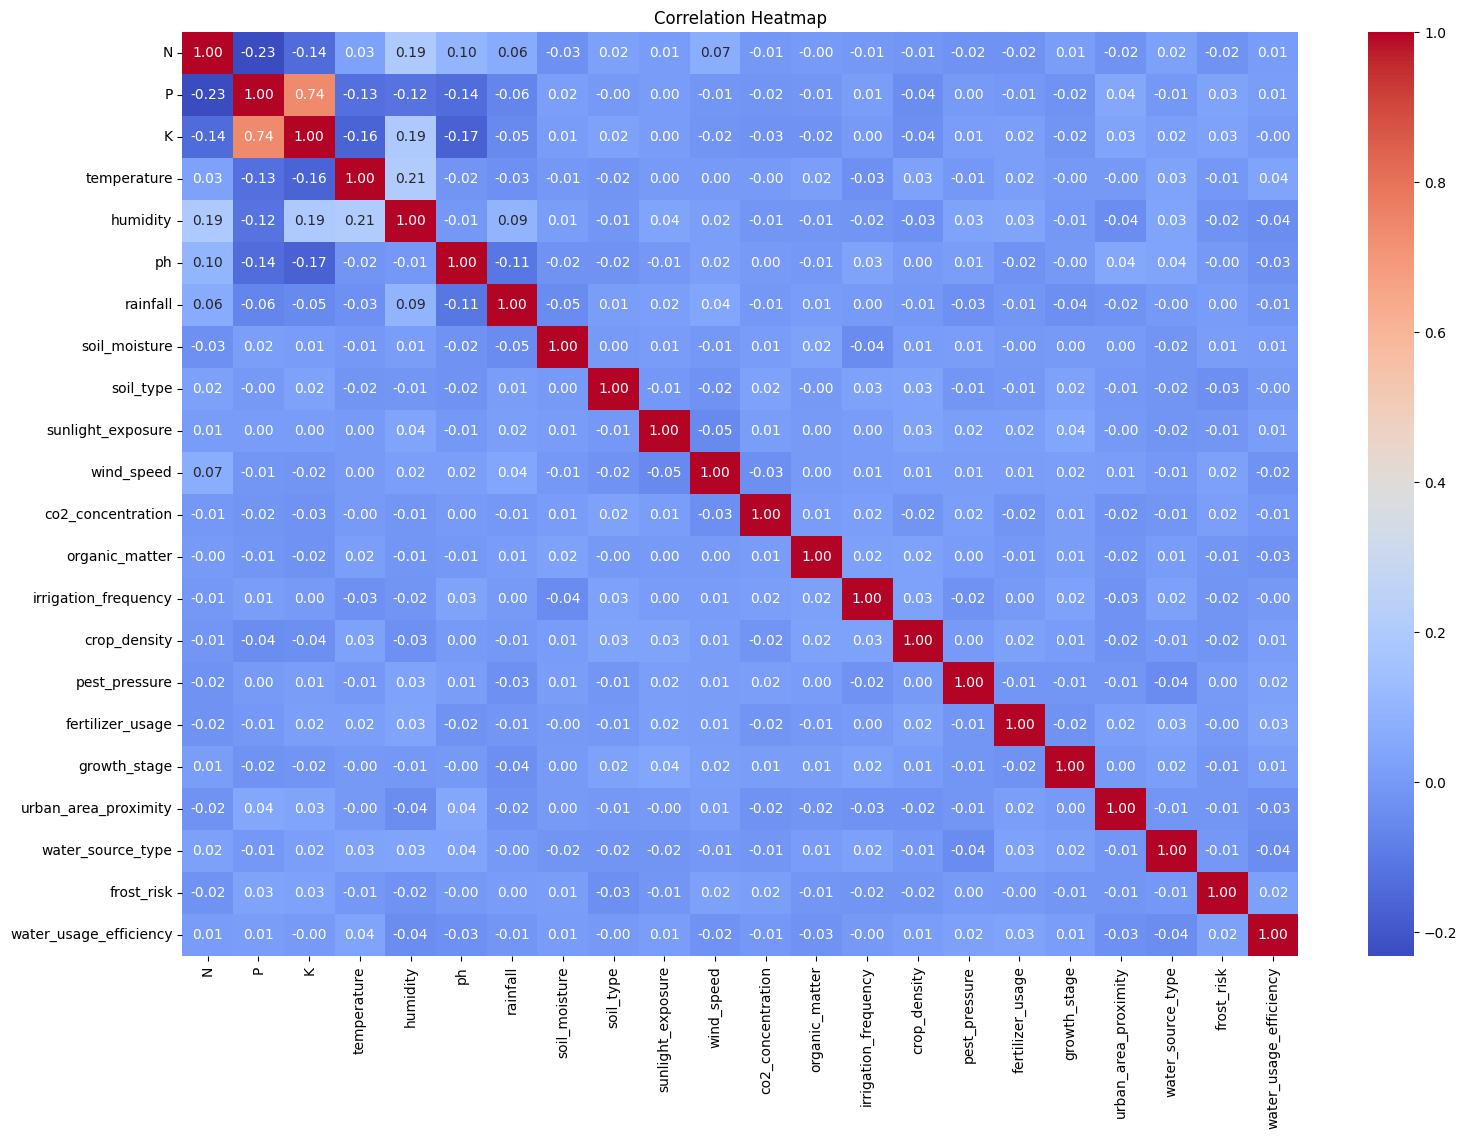

In [71]:
plt.figure(figsize=(18,12))
sns.heatmap(
    df.drop(columns='label').corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

*The correlation heatmap visualizes the strength and direction of linear relationships between numerical variables. Positive correlations indicate that two variables increase together, while negative correlations suggest that one decreases as the other increases. Variables with very high correlations may contain redundant information, which can influence model complexity. This visualization helps identify meaningful relationships, such as soil moisture and rainfall or nutrient interactions, while also guiding feature selection and engineering.*

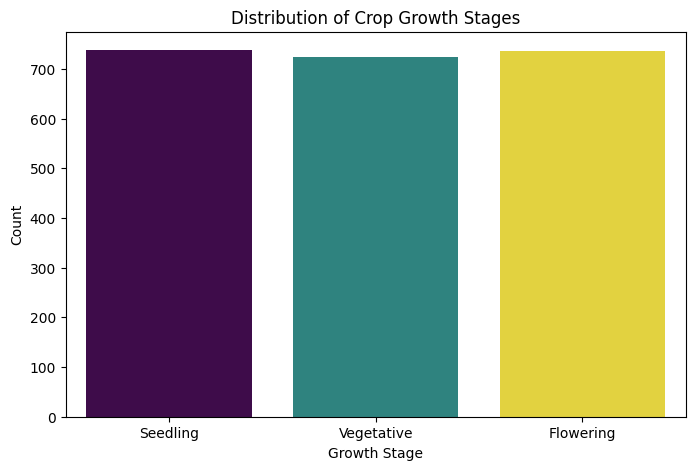

In [72]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='growth_stage',
    hue='growth_stage',
    palette='viridis',
    legend=False
)

plt.title("Distribution of Crop Growth Stages")
plt.xlabel("Growth Stage")
plt.ylabel("Count")
plt.xticks([0,1,2], ['Seedling','Vegetative','Flowering'])
plt.show()

*This chart displays the number of observations recorded for each crop growth stage. It helps determine whether all developmental stages are adequately represented within the dataset. A balanced distribution ensures that predictive models learn characteristics associated with each stage equally well, whereas an imbalance could reduce prediction accuracy for underrepresented stages. The visualization also provides insight into the overall composition of the agricultural observations.*

**Feature Engineering**

*Purpose of feature engineering is to create new features from the existing data.*

*creation of the derived features that are  mentioned in the project description.*

**Temperature-Humidity Index (THI)**

In [73]:
df['THI'] = df['temperature'] + (0.36 * df['humidity'])

*The code creates a new feature called Temperature-Humidity Index (THI) by combining the temperature and also the humidity.A higher THI value indicates warmer and more humid environmental conditions which may increase crop stress.This feature helps the machine learning models understand how the interaction between temperature and humidity affects crop growth rather than considering each variable separately.*

**Nutrient Balance Ratio (NBR)**

In [74]:
df['NBR'] = df['N'] / (df['P'] + df['K'] + 1)

*Instead of looking at Nitrogen, Phosphorus and Potassium separately, you are creating a feature that describes their relative balance.A high NBR means nitrogen is much higher than the combined phosphorus and potassium.A low NBR means nitrogen is low relative to phosphorus and potassium.*

**Water Availability Index (WAI)**

In [75]:
df['WAI'] = df['soil_moisture'] + df['rainfall']

*The code creates the Water Availability Index (WAI) by combining soil moisture and rainfall into a single feature representing the amount of water available for crops.Higher WAI values indicate greater water availability, while lower values may suggest drought conditions or insufficient water supply. This feature is useful for irrigation planning and water resource management.*

**Photosynthesis Potential (PP)**

In [76]:
df['PP'] = (
    df['sunlight_exposure'] *
    df['co2_concentration'] *
    df['temperature']
)

*The code creates a feature called Photosynthesis Potential (PP) by multiplying sunlight exposure, carbon dioxide concentration and temperature. In order for Photosynthesis to happen it depends on adequate sunlight, carbon dioxide and suitable temperatures. Higher PP values indicate conditions are more favorable for photosynthesis and plant growth. This engineered feature provides a single indicator of environmental conditions that influence crop development.*

**Soil Fertility Index (SFI)**

In [77]:
df['SFI'] = (
    df['organic_matter'] +
    df['N'] +
    df['P'] +
    df['K']
) / 4

*This code help's to create the feature called Soil Fertiliy Index(SFI) by calculating he average of organic matter, nitrogen, phosphorus, and potassium.High SFI means the soil is generally richer in nutrients and organic matter.Low SFI means the soil has lower average nutrient levels and organic matter.*

In [78]:
df[['THI', 'NBR', 'WAI', 'PP', 'SFI']].head()

,THI,NBR,WAI,PP,SFI
0,50.400732,1.046512,232.381600,78924.457463,44.530349
1,50.685534,0.850000,239.506720,50291.281753,46.535505
2,52.639934,0.600000,293.328160,81196.185258,40.118743
3,55.348107,0.973684,269.071767,77305.481013,39.348477
4,49.507929,0.917647,290.953577,67079.871968,41.800571


In [79]:
encoder = LabelEncoder()
df['label'] = encoder.fit_transform(df['label'])

In [80]:
X = df.drop('label', axis=1)
y = df['label']

In [81]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [82]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

**Model Building**

In [83]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

In [84]:
rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [85]:
gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)
gb_pred = gb.predict(X_test)

In [86]:
lr = LogisticRegression(
    max_iter=5000, # Increased max_iter to allow for convergence
    random_state=42
)
lr.fit(X_train_scaled, y_train)
lr_pred = lr.predict(X_test_scaled)

In [87]:
xgb = XGBClassifier(
    random_state=42,
    eval_metric='mlogloss'
)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

In [88]:
models = {
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Gradient Boosting": gb_pred,
    "Logistic Regression": lr_pred,
    "XGBoost": xgb_pred
}

for name, pred in models.items():
    print(name)
    print("Accuracy :", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred, average='weighted'))
    print("Recall   :", recall_score(y_test, pred, average='weighted'))
    print("F1 Score :", f1_score(y_test, pred, average='weighted'))

Decision Tree
Accuracy : 0.9795454545454545
Precision: 0.980499803227076
Recall   : 0.9795454545454545
F1 Score : 0.9795698588381515
Random Forest
Accuracy : 0.990909090909091
Precision: 0.991538764266037
Recall   : 0.990909090909091
F1 Score : 0.9908948561066662
Gradient Boosting
Accuracy : 0.9977272727272727
Precision: 0.9978354978354979
Recall   : 0.9977272727272727
F1 Score : 0.997725851384388
Logistic Regression
Accuracy : 0.975
Precision: 0.9762282773048324
Recall   : 0.975
F1 Score : 0.974839811393085
XGBoost
Accuracy : 0.9886363636363636
Precision: 0.9888528138528138
Recall   : 0.9886363636363636
F1 Score : 0.9886335209505941


**Feature Importance**

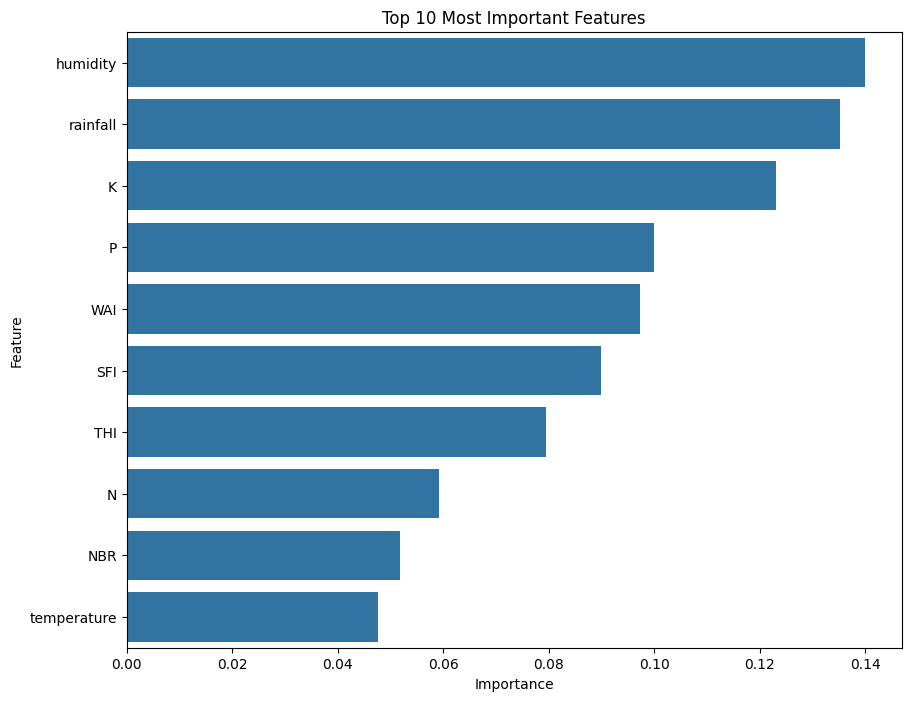

In [89]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)
plt.figure(figsize=(10,8))
sns.barplot(
    data=importance.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Most Important Features")
plt.show()

*The feature importance chart ranks the top variables that influenced the Random Forest crop classification model. Higher importance scores indicate that a feature contributed more to reducing classification error across the decision trees.This analysis is valuable for precision agriculture because it highlights which environmental and soil factors should be prioritized when making irrigation, fertilization, and crop selection decisions.*

In [90]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "Logistic Regression",
        "XGBoost"
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, gb_pred),
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, xgb_pred)
    ],
    "Precision": [
        precision_score(y_test, dt_pred, average='weighted'),
        precision_score(y_test, rf_pred, average='weighted'),
        precision_score(y_test, gb_pred, average='weighted'),
        precision_score(y_test, lr_pred, average='weighted'),
        precision_score(y_test, xgb_pred, average='weighted')
    ],
    "Recall": [
        recall_score(y_test, dt_pred, average='weighted'),
        recall_score(y_test, rf_pred, average='weighted'),
        recall_score(y_test, gb_pred, average='weighted'),
        recall_score(y_test, lr_pred, average='weighted'),
        recall_score(y_test, xgb_pred, average='weighted')
    ],
    "F1 Score": [
        f1_score(y_test, dt_pred, average='weighted'),
        f1_score(y_test, rf_pred, average='weighted'),
        f1_score(y_test, gb_pred, average='weighted'),
        f1_score(y_test, lr_pred, average='weighted'),
        f1_score(y_test, xgb_pred, average='weighted')
    ]
})

results

,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.979545,0.980500,0.979545,0.979570
1,Random Forest,0.990909,0.991539,0.990909,0.990895
2,Gradient Boosting,0.997727,0.997835,0.997727,0.997726
3,Logistic Regression,0.975000,0.976228,0.975000,0.974840
4,XGBoost,0.988636,0.988853,0.988636,0.988634


*Gradient Boosting is the best-performing model for this Smart Farming dataset because it achieved the highest values across all evaluation metrics. Its superior performance suggests that it is the most suitable model for supporting precision agriculture applications, including crop recommendation, irrigation planning, fertilizer management, and sustainable resource optimization. The consistently high performance of all models also demonstrates that the dataset contains informative features that enable accurate crop classification.*

**K-Means clustering**

In [91]:
cluster_features = df[
    [
        'N',
        'P',
        'K',
        'temperature',
        'humidity',
        'rainfall',
        'soil_moisture',
        'organic_matter'
    ]
]

In [92]:
scaler = StandardScaler()
cluster_scaled = scaler.fit_transform(cluster_features)

**Elbow method**

In [93]:
wcss = []
for i in range(1,11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42
    )

    kmeans.fit(cluster_scaled)

    wcss.append(kmeans.inertia_)

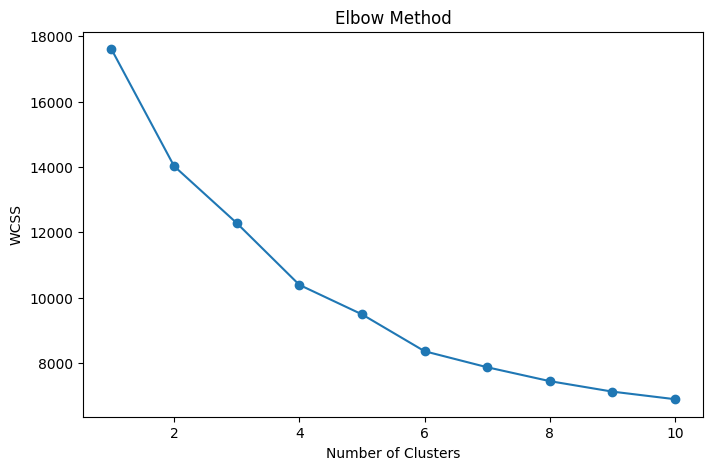

In [94]:
plt.figure(figsize=(8,5))
plt.plot(range(1,11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

*The elbow plot is used to determine the optimal number of clusters by observing where the decrease in WCSS begins to slow down. This point, known as the "elbow," indicates the number of clusters that best balances model simplicity and cluster quality.*

In [95]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42
)

df['KMeans_Cluster'] = kmeans.fit_predict(cluster_scaled)

In [96]:
df['KMeans_Cluster'].value_counts()

,count
KMeans_Cluster,
2,1335
1,665
0,200


In [97]:
score = silhouette_score(
    cluster_scaled,
    df['KMeans_Cluster']
)

print("Silhouette Score:", score)

Silhouette Score: 0.17636720038164805


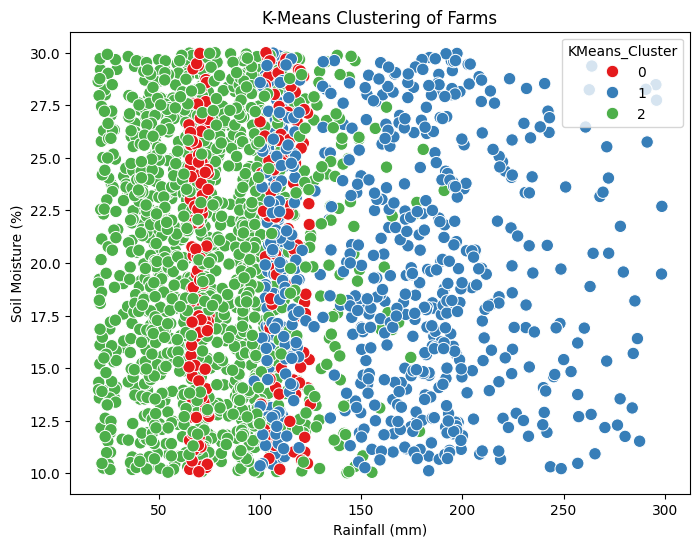

In [98]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x='rainfall',
    y='soil_moisture',
    hue='KMeans_Cluster',
    palette='Set1',
    s=80
)

plt.title("K-Means Clustering of Farms")

plt.xlabel("Rainfall (mm)")
plt.ylabel("Soil Moisture (%)")

plt.show()

*The scatter plot visualizes how farms are grouped based on rainfall and soil moisture after K-Means clustering. Farms within the same cluster exhibit similar environmental characteristics, while different clusters represent distinct agricultural conditions. These groupings can support targeted irrigation planning and resource allocation.*

In [99]:
dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

df['DBSCAN_Cluster'] = dbscan.fit_predict(cluster_scaled)

In [100]:
df['DBSCAN_Cluster'].value_counts()

,count
DBSCAN_Cluster,
-1,956
10,257
29,192
0,97
2,97
5,92
31,86
15,76
17,36


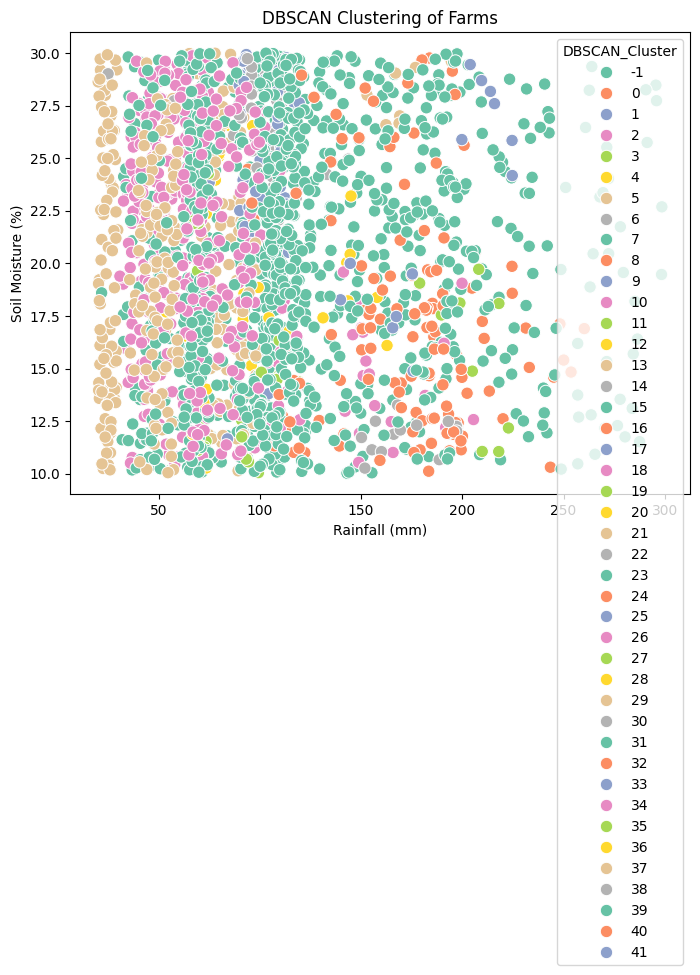

In [101]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='rainfall',
    y='soil_moisture',
    hue='DBSCAN_Cluster',
    palette='Set2',
    s=80
)

plt.title("DBSCAN Clustering of Farms")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Soil Moisture (%)")
plt.show()

*The DBSCAN visualization groups farms based on the density of observations rather than a predefined number of clusters. Unlike K-Means, DBSCAN can identify noise points (often labeled as -1), which may represent farms with unusual soil or environmental conditions. This makes it useful for detecting anomalies and understanding natural groupings within the dataset.*

**Use Cases**

*Precision Agriculture System*

In [102]:
df["Irrigation_Recommendation"] = np.where(
    (df["soil_moisture"] < 30) & (df["rainfall"] < 80),
    "Increase Irrigation",
    "Maintain Current Irrigation"
)

# Fertilizer Recommendation
median_fertilizer = df["fertilizer_usage"].median()

df["Fertilizer_Recommendation"] = np.where(
    df["fertilizer_usage"] < median_fertilizer,
    "Apply More Fertilizer",
    "Fertilizer Level Adequate"
)

# Pest Control Recommendation
df["Pest_Control_Recommendation"] = np.select(
    [
        df["pest_pressure"] < 3,
        (df["pest_pressure"] >= 3) & (df["pest_pressure"] < 7),
        df["pest_pressure"] >= 7
    ],
    [
        "Routine Monitoring",
        "Preventive Pest Control",
        "Immediate Pest Control"
    ],
    default='No specific recommendation' # Added a string default to match choicelist dtype
)

# Display Recommendations
recommendations = df[
    [
        "label",
        "Irrigation_Recommendation",
        "Fertilizer_Recommendation",
        "Pest_Control_Recommendation"
    ]
]

recommendations.head(10)

,label,Irrigation_Recommendation,Fertilizer_Recommendation,Pest_Control_Recommendation
0,20,Maintain Current Irrigation,Fertilizer Level Adequate,Immediate Pest Control
1,20,Maintain Current Irrigation,Apply More Fertilizer,Immediate Pest Control
2,20,Maintain Current Irrigation,Fertilizer Level Adequate,Routine Monitoring
3,20,Maintain Current Irrigation,Apply More Fertilizer,Immediate Pest Control
4,20,Maintain Current Irrigation,Fertilizer Level Adequate,Immediate Pest Control
5,20,Maintain Current Irrigation,Fertilizer Level Adequate,Immediate Pest Control
6,20,Maintain Current Irrigation,Apply More Fertilizer,Immediate Pest Control
7,20,Maintain Current Irrigation,Fertilizer Level Adequate,Immediate Pest Control
8,20,Maintain Current Irrigation,Apply More Fertilizer,Immediate Pest Control
9,20,Maintain Current Irrigation,Apply More Fertilizer,Immediate Pest Control


*The Precision Agriculture System successfully generated recommendations for irrigation, fertilizer application, and pest control based on soil and environmental conditions. Farms with low soil moisture and rainfall were identified as requiring increased irrigation, while fertilizer recommendations were determined by comparing fertilizer usage with the dataset's median value. Pest control recommendations were generated using the pest pressure index, enabling farms to be categorized according to the urgency of pest management. These results demonstrate how agricultural data can be transformed into practical decision support, helping farmers optimize resource use, improve crop productivity, and promote more sustainable farming practices.*

*Crop Stress Detection*

In [103]:
df["Crop_Stress"] = np.select(
    [
        (df["temperature"] > 35) | (df["frost_risk"] > 0.7),
        ((df["temperature"] >= 30) & (df["temperature"] <= 35)) |
        ((df["humidity"] < 40) & (df["frost_risk"] <= 0.7))
    ],
    [
        "High Stress",
        "Moderate Stress"
    ],
    default="Low Stress"
)

# Display Stress Levels
df[["label", "temperature", "humidity", "frost_risk", "Crop_Stress"]].head(10)

,label,temperature,humidity,frost_risk,Crop_Stress
0,20,20.879744,82.002744,95.649985,High Stress
1,20,21.770462,80.319644,77.265694,High Stress
2,20,23.004459,82.320763,18.192168,High Stress
3,20,26.491096,80.158363,82.818720,High Stress
4,20,20.130175,81.604873,25.466499,High Stress
5,20,23.058049,83.370118,43.426334,High Stress
6,20,22.708838,82.639414,50.018971,High Stress
7,20,20.277744,82.894086,18.089962,High Stress
8,20,24.515881,83.535216,98.377409,High Stress
9,20,23.223974,83.033227,63.335752,High Stress


*The Crop Stress Detection system classifies environmental conditions into Low, Moderate, and High Stress levels using temperature, humidity, and frost risk. Crops exposed to very high temperatures or high frost risk are classified as experiencing high stress, while moderate environmental conditions are classified as moderate stress. This analysis helps identify farms that may require immediate intervention, such as increased irrigation or protective measures, to reduce environmental stress and improve crop health.*

*Sustainable Resource Management*

In [104]:
# Water Management Recommendation
df["Water_Management"] = np.where(
    df["water_usage_efficiency"] > df["water_usage_efficiency"].median(),
    "Improve Water Efficiency",
    "Water Usage Efficient"
)

# Fertilizer Management Recommendation
df["Fertilizer_Management"] = np.where(
    df["fertilizer_usage"] > df["fertilizer_usage"].median(),
    "Reduce Fertilizer Usage",
    "Optimal Fertilizer Usage"
)

# Soil Moisture Management Recommendation
df["Soil_Management"] = np.where(
    df["soil_moisture"] < 30,
    "Increase Soil Moisture",
    "Soil Moisture Adequate"
)

# Display Results
resource_management = df[
    [
        "label",
        "Water_Management",
        "Fertilizer_Management",
        "Soil_Management"
    ]
]

resource_management.head(10)

,label,Water_Management,Fertilizer_Management,Soil_Management
0,20,Water Usage Efficient,Reduce Fertilizer Usage,Increase Soil Moisture
1,20,Water Usage Efficient,Optimal Fertilizer Usage,Increase Soil Moisture
2,20,Improve Water Efficiency,Reduce Fertilizer Usage,Increase Soil Moisture
3,20,Water Usage Efficient,Optimal Fertilizer Usage,Increase Soil Moisture
4,20,Water Usage Efficient,Reduce Fertilizer Usage,Increase Soil Moisture
5,20,Water Usage Efficient,Reduce Fertilizer Usage,Increase Soil Moisture
6,20,Improve Water Efficiency,Optimal Fertilizer Usage,Increase Soil Moisture
7,20,Improve Water Efficiency,Reduce Fertilizer Usage,Increase Soil Moisture
8,20,Water Usage Efficient,Optimal Fertilizer Usage,Increase Soil Moisture
9,20,Improve Water Efficiency,Optimal Fertilizer Usage,Increase Soil Moisture


*The Sustainable Resource Management system evaluates water usage efficiency, fertilizer application, and soil moisture to generate practical management recommendations. Farms with inefficient water use are advised to improve water efficiency, while those applying fertilizer above the dataset's median level are recommended to reduce fertilizer usage to minimize waste. Soil moisture recommendations identify farms that may require additional irrigation to maintain healthy growing conditions. These results demonstrate how real-time soil and environmental data can support more efficient resource utilization, reduce unnecessary input costs, and promote sustainable agricultural practices.*

*Smart Irrigation Solutions*

In [105]:
# Smart Irrigation Solution
conditions = [
    (df["soil_moisture"] < 30) & (df["rainfall"] < 50),
    (df["soil_moisture"] < 30) & (df["rainfall"] >= 50),
    (df["soil_moisture"] >= 30) & (df["soil_moisture"] <= 60) & (df["rainfall"] < 80),
    (df["soil_moisture"] > 60) | (df["rainfall"] >= 80)
]

recommendations = [
    "High Irrigation Required",
    "Moderate Irrigation Required",
    "Maintain Current Irrigation",
    "Stop Irrigation"
]

df["Smart_Irrigation_System"] = np.select(
    conditions,
    recommendations,
    default="Monitor Field Conditions"
)

df[[
    "soil_moisture",
    "rainfall",
    "Smart_Irrigation_System"
]].head(10)

,soil_moisture,rainfall,Smart_Irrigation_System
0,29.446064,202.935536,Moderate Irrigation Required
1,12.851183,226.655537,Moderate Irrigation Required
2,29.363913,263.964248,Moderate Irrigation Required
3,26.207732,242.864034,Moderate Irrigation Required
4,28.236236,262.717340,Moderate Irrigation Required
5,23.613115,251.055000,Moderate Irrigation Required
6,15.333693,271.324860,Moderate Irrigation Required
7,20.835640,241.974195,Moderate Irrigation Required
8,26.640656,230.446236,Moderate Irrigation Required
9,24.368853,221.209196,Moderate Irrigation Required


*The Smart Irrigation System adapts irrigation recommendations according to both soil moisture and rainfall conditions. Farms with low soil moisture and little rainfall are recommended to apply high levels of irrigation, while farms receiving adequate rainfall or having high soil moisture are advised to reduce or stop irrigation. Farms with moderate conditions are encouraged to maintain their current irrigation schedule. This adaptive approach demonstrates how environmental data can be used to support intelligent irrigation decisions, improve water conservation, and ensure crops receive sufficient water without unnecessary irrigation.*

*Pest Management Optimization*

In [106]:
# Pest Management Early Warning System
conditions = [
    (df["pest_pressure"] >= 7) &
    (df["temperature"] > 30) &
    (df["humidity"] > 70),

    (df["pest_pressure"] >= 4) &
    (df["temperature"] > 25),

    (df["pest_pressure"] < 4)
]

warnings = [
    "High Risk - Immediate Action Required",
    "Moderate Risk - Monitor Crops Closely",
    "Low Risk - Continue Routine Monitoring"
]

df["Pest_Warning"] = np.select(
    conditions,
    warnings,
    default="Monitor Environmental Conditions"
)

# Display Results
df[
    [
        "label",
        "temperature",
        "humidity",
        "pest_pressure",
        "Pest_Warning"
    ]
].head(10)

,label,temperature,humidity,pest_pressure,Pest_Warning
0,20,20.879744,82.002744,57.607308,Monitor Environmental Conditions
1,20,21.770462,80.319644,74.736879,Monitor Environmental Conditions
2,20,23.004459,82.320763,1.034478,Low Risk - Continue Routine Monitoring
3,20,26.491096,80.158363,24.091888,Moderate Risk - Monitor Crops Closely
4,20,20.130175,81.604873,38.811481,Monitor Environmental Conditions
5,20,23.058049,83.370118,82.073413,Monitor Environmental Conditions
6,20,22.708838,82.639414,48.814626,Monitor Environmental Conditions
7,20,20.277744,82.894086,80.127831,Monitor Environmental Conditions
8,20,24.515881,83.535216,89.870192,Monitor Environmental Conditions
9,20,23.223974,83.033227,26.544258,Monitor Environmental Conditions


*The Pest Management Early Warning System evaluates pest pressure together with environmental conditions such as temperature and humidity to classify farms into different pest outbreak risk levels. Farms with high pest pressure, elevated temperatures, and high humidity are identified as high-risk and require immediate pest control measures. Moderate-risk farms are advised to closely monitor crop conditions, while low-risk farms continue routine monitoring. This system demonstrates how environmental data can be combined with pest pressure indices to provide early warnings, enabling timely interventions that reduce crop damage and improve agricultural productivity.*

*Climate Resilience Research*

In [107]:
# Climate Resilience Research
conditions = [
    (df["temperature"] > 35),
    (df["rainfall"] > 200),
    (df["frost_risk"] > 0.7)
]

weather_condition = [
    "Heat Stress",
    "Heavy Rainfall",
    "High Frost Risk"
]

df["Extreme_Weather"] = np.select(
    conditions,
    weather_condition,
    default="Normal Conditions"
)

# Climate Resilience Strategy
df["Resilience_Strategy"] = np.select(
    [
        df["Extreme_Weather"] == "Heat Stress",
        df["Extreme_Weather"] == "Heavy Rainfall",
        df["Extreme_Weather"] == "High Frost Risk"
    ],
    [
        "Increase Irrigation and Use Heat-Tolerant Crops",
        "Improve Drainage and Reduce Waterlogging",
        "Use Frost Protection Measures"
    ],
    default="Continue Standard Farming Practices"
)

# Display Results
climate_resilience = df[
    [
        "label",
        "temperature",
        "rainfall",
        "frost_risk",
        "Extreme_Weather",
        "Resilience_Strategy"
    ]
]

climate_resilience.head(10)

,label,temperature,rainfall,frost_risk,Extreme_Weather,Resilience_Strategy
0,20,20.879744,202.935536,95.649985,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
1,20,21.770462,226.655537,77.265694,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
2,20,23.004459,263.964248,18.192168,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
3,20,26.491096,242.864034,82.818720,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
4,20,20.130175,262.717340,25.466499,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
5,20,23.058049,251.055000,43.426334,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
6,20,22.708838,271.324860,50.018971,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
7,20,20.277744,241.974195,18.089962,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
8,20,24.515881,230.446236,98.377409,Heavy Rainfall,Improve Drainage and Reduce Waterlogging
9,20,23.223974,221.209196,63.335752,Heavy Rainfall,Improve Drainage and Reduce Waterlogging


*The Climate Resilience Research system analyzes crop-growing conditions by evaluating temperature, rainfall, and frost risk to identify exposure to extreme weather events. Farms experiencing heat stress, excessive rainfall, or high frost risk are assigned resilience strategies such as increasing irrigation, improving drainage, or implementing frost protection measures. These recommendations help farmers adapt to changing environmental conditions, reduce the impact of climate-related risks, and improve long-term agricultural productivity and sustainability.*